In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/1102965003523296.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/1500419800753647.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/193342792634899.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/208839637427980.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/324819912392369.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/3428142287286692.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/372500500837473.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/460428965043069.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/47

## Find manifest path and confirm the images match the path

In [2]:
import csv
from collections import Counter
from pathlib import Path
from PIL import Image

manifest_files = list(
    Path("/kaggle/input").rglob("manifest_split.csv")
)

print("Found:", manifest_files)

if len(manifest_files) != 1:
    raise ValueError(
        f"Expected one manifest, found {len(manifest_files)}. "
        "Check the paths above."
    )

MANIFEST_PATH = manifest_files[0]
DATA_ROOT = MANIFEST_PATH.parent.parent

print("Manifest:", MANIFEST_PATH)
print("Project directory:", DATA_ROOT)

Found: [PosixPath('/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv')]
Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Project directory: /kaggle/input/datasets/nguyen700/road-types-dataset


## Check if image paths match the path in manifest

In [3]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

missing_images = []

with MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)

    if "image_path" not in (reader.fieldnames or []):
        raise ValueError("Manifest is missing the image_path column.")

    rows = list(reader)

for row in rows:
    relative_path = row["image_path"].strip()
    image_path = DATA_ROOT / relative_path

    if not relative_path or not image_path.is_file():
        missing_images.append({
            "image_id": row.get("image_id", ""),
            "path": str(image_path),
        })

print("Manifest:", MANIFEST_PATH)
print("Total images:", len(rows))
print("Existing images:", len(rows) - len(missing_images))
print("Missing images:", len(missing_images))

for item in missing_images:
    print("Missing:", item["image_id"], item["path"])

if not rows:
    raise ValueError("Manifest is empty.")

if missing_images:
    raise FileNotFoundError("Fix missing image paths before continuing.")

Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Total images: 3385
Existing images: 3385
Missing images: 0


In [4]:
# 1. Đọc toàn bộ manifest và kiểm tra cấu trúc cột
with Path(MANIFEST_PATH).open(encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    columns = reader.fieldnames
    rows = list(reader)

print("Các cột trong manifest_split.csv:", columns)
print("Tổng số dòng:", len(rows))
print("Ví dụ dòng đầu tiên:", rows[0])

# 2. Kiểm tra phân bố các tập split 
split_counts = Counter(r["split"].strip() for r in rows)
print("\n--- Số lượng ảnh theo từng split ---")
for sp, cnt in split_counts.items():
    print(f"  {sp}: {cnt} ảnh")

# Kiểm tra tên cột chứa nhãn chữ (nếu có) và class_id
label_col = next((c for c in ["class_name", "label", "surface", "category"] if c in columns), None)

print("\n--- Phân bố lớp trong từng split ---")
for sp in split_counts:
    sub = [r for r in rows if r["split"].strip() == sp]
    if label_col:
        dist = Counter((int(r["class_id"]), r[label_col].strip()) for r in sub)
    else:
        dist = Counter(int(r["class_id"]) for r in sub)
    print(f"  [{sp}]: {dict(sorted(dist.items()))}")

# 3. Kiểm tra kích thước (W, H), hệ màu (mode) và file hỏng trên TOÀN BỘ ảnh
size_counts = Counter()
mode_counts = Counter()
corrupted_files = []

for r in rows:
    img_path = Path(DATA_ROOT) / r["image_path"].strip()
    try:
        with Image.open(img_path) as img:
            size_counts[img.size] += 1   # img.size trả về (width, height)
            mode_counts[img.mode] += 1   # 'RGB', 'L', 'RGBA'...
    except Exception as e:
        corrupted_files.append((str(img_path), str(e)))

print("\n--- Thống kê kích thước ảnh (Width, Height) ---")
print(f"Tổng số loại kích thước khác nhau: {len(size_counts)}")
for sz, cnt in size_counts.most_common(10):
    print(f"  {sz}: {cnt} ảnh")

print("\n--- Thống kê hệ màu (Mode) ---")
for md, cnt in mode_counts.items():
    print(f"  {md}: {cnt} ảnh")

print(f"\n--- Số ảnh bị lỗi/không mở được: {len(corrupted_files)} ---")
if corrupted_files:
    print("  Ví dụ file lỗi:", corrupted_files[:5])

Các cột trong manifest_split.csv: ['image_id', 'image_path', 'label', 'class_id', 'split', 'longitude', 'latitude', 'captured_at', 'group_id', 'source', 'license', 'region', 'osm_way_id', 'osm_surface', 'sequence_id', 'creator', 'source_url', 'creator_url', 'osm_way_url']
Tổng số dòng: 3385
Ví dụ dòng đầu tiên: {'image_id': '1000927687276860', 'image_path': 'outputs/preprocessed/1000927687276860.png', 'label': 'concrete', 'class_id': '1', 'split': 'train', 'longitude': '13.287804599998', 'latitude': '51.5025968', 'captured_at': '1655735677353', 'group_id': 'geo_0', 'source': 'street_surface_vis', 'license': '', 'region': '', 'osm_way_id': '', 'osm_surface': '', 'sequence_id': '', 'creator': '', 'source_url': '', 'creator_url': '', 'osm_way_url': ''}

--- Số lượng ảnh theo từng split ---
  train: 2708 ảnh
  validation: 339 ảnh
  test: 338 ảnh

--- Phân bố lớp trong từng split ---
  [train]: {(0, 'unpaved'): 819, (1, 'concrete'): 788, (2, 'sett'): 1101}
  [validation]: {(0, 'unpaved'): 1

## Trích xuất đặc trưng HOG + Color Histogram

In [5]:
import cv2
import numpy as np
from skimage.feature import hog
from tqdm.auto import tqdm

IMG_SIZE = (128, 128)   
HIST_BINS = 16          

def extract_single_feature(img_path):
    img = cv2.imread(str(img_path))
    img = cv2.resize(img, IMG_SIZE)

    # 1. Trích xuất HOG trên ảnh xám
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hog_feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )
    hog_feat = hog_feat / (np.linalg.norm(hog_feat) + 1e-7)

    # 2. Trích xuất Color Histogram trên không gian màu HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [HIST_BINS], [0, 180]).flatten()
    hist_s = cv2.calcHist([hsv], [1], None, [HIST_BINS], [0, 256]).flatten()
    hist_v = cv2.calcHist([hsv], [2], None, [HIST_BINS], [0, 256]).flatten()
    hist_feat = np.concatenate([hist_h, hist_s, hist_v])
    hist_feat = hist_feat / (np.linalg.norm(hist_feat) + 1e-7)

    # 3. Ghép 2 vector đặc trưng
    return np.concatenate([hog_feat, hist_feat]).astype(np.float32)

def build_split_features(rows, data_root, split_name):
    sub_rows = [r for r in rows if r["split"].strip() == split_name]
    X_list, y_list = [], []
    
    for r in tqdm(sub_rows, desc=f"Extracting {split_name}"):
        img_path = Path(data_root) / r["image_path"].strip()
        feat = extract_single_feature(img_path)
        X_list.append(feat)
        y_list.append(int(r["class_id"]))
        
    return np.array(X_list), np.array(y_list, dtype=np.int64)

# Chạy trích xuất cho cả 3 tập và lưu ra /kaggle/working/
for split in ["train", "validation", "test"]:
    X, y = build_split_features(rows, DATA_ROOT, split)
    np.save(f"/kaggle/working/X_{split}.npy", X)
    np.save(f"/kaggle/working/y_{split}.npy", y)
    print(f"Saved {split}: X={X.shape}, y={y.shape}")

Extracting train:   0%|          | 0/2708 [00:00<?, ?it/s]

Saved train: X=(2708, 8148), y=(2708,)


Extracting validation:   0%|          | 0/339 [00:00<?, ?it/s]

Saved validation: X=(339, 8148), y=(339,)


Extracting test:   0%|          | 0/338 [00:00<?, ?it/s]

Saved test: X=(338, 8148), y=(338,)


## Tinh chỉnh nhẹ & Chạy bảng đối chứng (Ablation Study)

In [6]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

X_train = np.load("/kaggle/working/X_train.npy")
y_train = np.load("/kaggle/working/y_train.npy")
X_val   = np.load("/kaggle/working/X_validation.npy")
y_val   = np.load("/kaggle/working/y_validation.npy")

HOG_DIM = 8100

def select_features(X, feat_key):
    """Cắt ma trận đặc trưng theo đúng loại biểu diễn."""
    if feat_key == "hsv":
        return X[:, HOG_DIM:]       # 48 chiều cuối
    elif feat_key == "hog":
        return X[:, :HOG_DIM]       # 8100 chiều đầu
    elif feat_key == "hog_hsv":
        return X                    # Toàn bộ 8148 chiều
    else:
        raise ValueError(f"Unknown feat_key: {feat_key}")

# 1. Ba cách biểu diễn đặc trưng dùng chung để so sánh công bằng giữa SVM và KNN
representations = [
    ("hsv",     "HSV Histogram (48D)"),
    ("hog",     "HOG (8100D)"),
    ("hog_hsv", "HOG + HSV (8148D)"),
]

# 2. Danh sách cấu hình cho SVM
svm_configs = [
    ("Linear (C=0.1)", SVC(kernel="linear", C=0.1, class_weight="balanced", random_state=42)),
    ("Linear (C=1.0)", SVC(kernel="linear", C=1.0, class_weight="balanced", random_state=42)),
    ("RBF (C=1.0)",    SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)),
    ("RBF (C=3.0)",    SVC(kernel="rbf", C=3.0, gamma="scale", class_weight="balanced", random_state=42)),
    ("RBF (C=5.0)",    SVC(kernel="rbf", C=5.0, gamma="scale", class_weight="balanced", random_state=42)),
]

# 3. Danh sách cấu hình cho KNN (k = 1..10, weights in ['uniform', 'distance'], euclidean, brute)
knn_configs = [
    (
        f"KNN (k={k}, {w})",
        KNeighborsClassifier(
            n_neighbors=k,
            weights=w,
            metric="euclidean",
            algorithm="brute",
            n_jobs=-1,
        ),
    )
    for w in ["uniform", "distance"]
    for k in range(1, 11)
]

model_suites = {
    "SVM": svm_configs,
    "KNN": knn_configs,
}

records = []
best_models = {}  # Lưu cấu hình thắng cuộc cho từng thuật toán ('SVM' và 'KNN')

for model_name, configs in model_suites.items():
    print(f"\n=====================================================================")
    print(f"ĐANG ĐÁNH GIÁ THUẬT TOÁN: {model_name} ({len(representations)} biểu diễn x {len(configs)} cấu hình)")
    print(f"=====================================================================")
    
    best_f1 = -1.0
    best_info = None
    
    for feat_key, feat_name in representations:
        print(f"\n--- [{model_name}] Biểu diễn: {feat_name} ---")
        X_tr_sub = select_features(X_train, feat_key)
        X_va_sub = select_features(X_val, feat_key)
        
        for cfg_name, clf in configs:
            model = clone(clf)
            model.fit(X_tr_sub, y_train)
            
            # Đánh giá trên Train
            tr_pred = model.predict(X_tr_sub)
            tr_acc = accuracy_score(y_train, tr_pred)
            tr_f1  = f1_score(y_train, tr_pred, average="macro")
            
            # Đánh giá trên Validation
            va_pred = model.predict(X_va_sub)
            va_acc = accuracy_score(y_val, va_pred)
            va_rec = recall_score(y_val, va_pred, average="macro")
            va_f1  = f1_score(y_val, va_pred, average="macro")
            
            print(
                f"{cfg_name:<22} | Train Acc: {tr_acc:.4f} | "
                f"Val Acc: {va_acc:.4f} | Val Recall: {va_rec:.4f} | Val F1: {va_f1:.4f}"
            )
            
            records.append({
                "Model": model_name,
                "feat_key": feat_key,
                "Representation": feat_name,
                "Config": cfg_name,
                "Train_Acc": tr_acc,
                "Train_F1": tr_f1,
                "Val_Acc": va_acc,
                "Val_Recall": va_rec,
                "Val_F1": va_f1,
            })
            
            if va_f1 > best_f1:
                best_f1 = va_f1
                best_info = {
                    "model_name": model_name,
                    "feat_key": feat_key,
                    "feat_name": feat_name,
                    "cfg_name": cfg_name,
                    "clf": clone(clf),
                    "val_f1": va_f1,
                }
                
    best_models[model_name] = best_info

# Xuất bảng tóm tắt cấu hình tốt nhất của TỪNG thuật toán trên TỪNG cách biểu diễn
results_df = pd.DataFrame(records)
print("\n=== TỔNG HỢP CẤU HÌNH TỐT NHẤT THEO TỪNG THUẬT TOÁN & BIỂU DIỄN (VALIDATION) ===")
best_per_group = (
    results_df.sort_values(by=["Val_F1", "Val_Acc"], ascending=False)
    .groupby(["Model", "Representation"], as_index=False, sort=False)
    .first()
)
for _, row in best_per_group.iterrows():
    print(
        f"[{row['Model']:<3}] {row['Representation']:<20} | Best: {row['Config']:<22} | "
        f"Val Acc: {row['Val_Acc']:.4f} | Val Recall: {row['Val_Recall']:.4f} | Val F1: {row['Val_F1']:.4f}"
    )

print("\n==> CHỐT PHƯƠNG ÁN TỐT NHẤT CHO TỪNG THUẬT TOÁN:")
for m_name, info in best_models.items():
    print(f"  * {m_name:<3}: [{info['feat_name']}] + [{info['cfg_name']}] (Val Macro F1 = {info['val_f1']:.4f})")

results_df.to_csv("/kaggle/working/ablation_svm_knn_results.csv", index=False)


ĐANG ĐÁNH GIÁ THUẬT TOÁN: SVM (3 biểu diễn x 5 cấu hình)

--- [SVM] Biểu diễn: HSV Histogram (48D) ---
Linear (C=0.1)         | Train Acc: 0.5990 | Val Acc: 0.5664 | Val Recall: 0.5594 | Val F1: 0.5622
Linear (C=1.0)         | Train Acc: 0.6174 | Val Acc: 0.5664 | Val Recall: 0.5629 | Val F1: 0.5613
RBF (C=1.0)            | Train Acc: 0.7411 | Val Acc: 0.6254 | Val Recall: 0.6239 | Val F1: 0.6233
RBF (C=3.0)            | Train Acc: 0.7954 | Val Acc: 0.6136 | Val Recall: 0.6149 | Val F1: 0.6114
RBF (C=5.0)            | Train Acc: 0.8294 | Val Acc: 0.6254 | Val Recall: 0.6265 | Val F1: 0.6230

--- [SVM] Biểu diễn: HOG (8100D) ---
Linear (C=0.1)         | Train Acc: 0.6647 | Val Acc: 0.5782 | Val Recall: 0.5995 | Val F1: 0.5725
Linear (C=1.0)         | Train Acc: 0.8213 | Val Acc: 0.7139 | Val Recall: 0.7230 | Val F1: 0.7137
RBF (C=1.0)            | Train Acc: 0.9690 | Val Acc: 0.7493 | Val Recall: 0.7511 | Val F1: 0.7470
RBF (C=3.0)            | Train Acc: 1.0000 | Val Acc: 0.7729 | Val

## Đánh giá cuối cùng


================ KẾT QUẢ TẬP TEST: SVM ================
Biểu diễn sử dụng: HOG + HSV (8148D)
Cấu hình sử dụng : RBF (C=5.0)
Test Accuracy    : 0.8639
Test Macro Recall: 0.8579
Test Macro F1    : 0.8609

              precision    recall  f1-score   support

     unpaved     0.8866    0.8431    0.8643       102
    concrete     0.8526    0.8182    0.8351        99
        sett     0.8562    0.9124    0.8834       137

    accuracy                         0.8639       338
   macro avg     0.8651    0.8579    0.8609       338
weighted avg     0.8643    0.8639    0.8635       338

Ví dụ đầu ra xác suất (%) mẫu test[0] (SVM): {'unpaved': 4.05, 'concrete': 1.27, 'sett': 94.68}
Đã lưu bundle SVM tại: /kaggle/working/best_road_svm_bundle.joblib

================ KẾT QUẢ TẬP TEST: KNN ================
Biểu diễn sử dụng: HSV Histogram (48D)
Cấu hình sử dụng : KNN (k=7, distance)
Test Accuracy    : 0.6124
Test Macro Recall: 0.5806
Test Macro F1    : 0.5767

              precision    recall  f1-

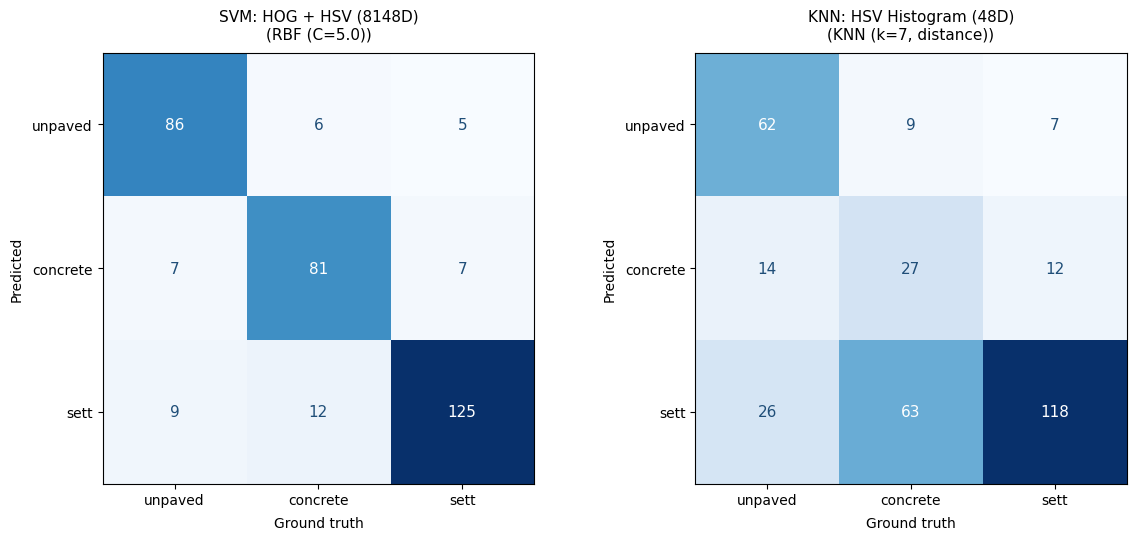

In [7]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

X_test = np.load("/kaggle/working/X_test.npy")
y_test = np.load("/kaggle/working/y_test.npy")
CLASS_NAMES = ["unpaved", "concrete", "sett"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
test_predictions = {}  # Lưu lại dự đoán nếu Cell 9 cần dùng

for idx, model_name in enumerate(["SVM", "KNN"]):
    info = best_models[model_name]
    feat_key  = info["feat_key"]
    feat_name = info["feat_name"]
    cfg_name  = info["cfg_name"]
    
    # Cắt đúng chiều đặc trưng của thuật toán tương ứng
    X_train_sub = select_features(X_train, feat_key)
    X_test_sub  = select_features(X_test, feat_key)
    
    clf = clone(info["clf"])
    # Với SVM cần bật probability=True; với KNN thì predict_proba() đã có sẵn mặc định
    if model_name == "SVM":
        clf.set_params(probability=True)
        
    clf.fit(X_train_sub, y_train)
    
    y_test_pred  = clf.predict(X_test_sub)
    y_test_proba = clf.predict_proba(X_test_sub)  # Ma trận xác suất (N, 3)
    test_predictions[model_name] = y_test_pred
    
    test_acc = accuracy_score(y_test, y_test_pred)
    test_rec = recall_score(y_test, y_test_pred, average="macro")
    test_f1  = f1_score(y_test, y_test_pred, average="macro")
    
    print(f"\n================ KẾT QUẢ TẬP TEST: {model_name} ================")
    print(f"Biểu diễn sử dụng: {feat_name}")
    print(f"Cấu hình sử dụng : {cfg_name}")
    print(f"Test Accuracy    : {test_acc:.4f}")
    print(f"Test Macro Recall: {test_rec:.4f}")
    print(f"Test Macro F1    : {test_f1:.4f}\n")
    print(classification_report(y_test, y_test_pred, target_names=CLASS_NAMES, digits=4))
    
    sample_probs = {CLASS_NAMES[i]: round(float(y_test_proba[0][i]) * 100, 2) for i in range(len(CLASS_NAMES))}
    print(f"Ví dụ đầu ra xác suất (%) mẫu test[0] ({model_name}): {sample_probs}")
    
    # Vẽ Confusion Matrix lên subplot tương ứng
    cm = confusion_matrix(y_test_pred, y_test)
    ax = axes[idx]
    ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    ax.set_title(f"{model_name}: {feat_name}\n({cfg_name})", fontsize=11, pad=10)
    
    tick_marks = np.arange(len(CLASS_NAMES))
    ax.set_xticks(tick_marks)
    ax.set_xticklabels(CLASS_NAMES, fontsize=10)
    ax.set_yticks(tick_marks)
    ax.set_yticklabels(CLASS_NAMES, fontsize=10)
    ax.set_ylabel("Predicted", fontsize=10, labelpad=6)
    ax.set_xlabel("Ground truth", fontsize=10, labelpad=6)
    
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                fontsize=11,
                color="white" if cm[i, j] > thresh else "#1f4e78"
            )
            
    # Lưu file .joblib đồng nhất cấu trúc cho từng thuật toán
    model_path = f"/kaggle/working/best_road_{model_name.lower()}_bundle.joblib"
    model_bundle = {
        "model_family": model_name,       # 'SVM' hoặc 'KNN'
        "model": clf,                     # Đã hỗ trợ sẵn .predict_proba()
        "feature_type": feat_key,         # 'hsv', 'hog', hoặc 'hog_hsv'
        "feature_name": feat_name,
        "config_name": cfg_name,
        "img_size": (128, 128),
        "hist_bins": 16,
        "class_names": CLASS_NAMES,
    }
    joblib.dump(model_bundle, model_path)
    print(f"Đã lưu bundle {model_name} tại: {model_path}")

plt.tight_layout()
cm_fig_path = "/kaggle/working/confusion_matrix_svm_vs_knn.png"
plt.savefig(cm_fig_path, dpi=200, bbox_inches="tight")
plt.show()

## Kiểm tra ảnh lỗi


THỐNG KÊ TỔNG HỢP LỖI TRÊN TẬP TEST (TỔNG SỐ: 338 ẢNH)
1. Tổng số ảnh SVM đoán sai       :  46/338 (13.61%)
2. Tổng số ảnh KNN đoán sai       : 131/338 (38.76%)
-------------------------------------------------------------------------
3. Cả SVM và KNN cùng đoán sai    :  37/338 (10.95%)
4. Chỉ KNN sai, SVM đoán đúng     :  94/338 (27.81%)
5. Chỉ SVM sai, KNN đoán đúng     :   9/338 (2.66%)
6. Cả SVM và KNN cùng đoán đúng   : 198/338 (58.58%)

Đã xuất log chi tiết 140 ảnh lỗi tại: /kaggle/working/error_comparison_log_test.csv



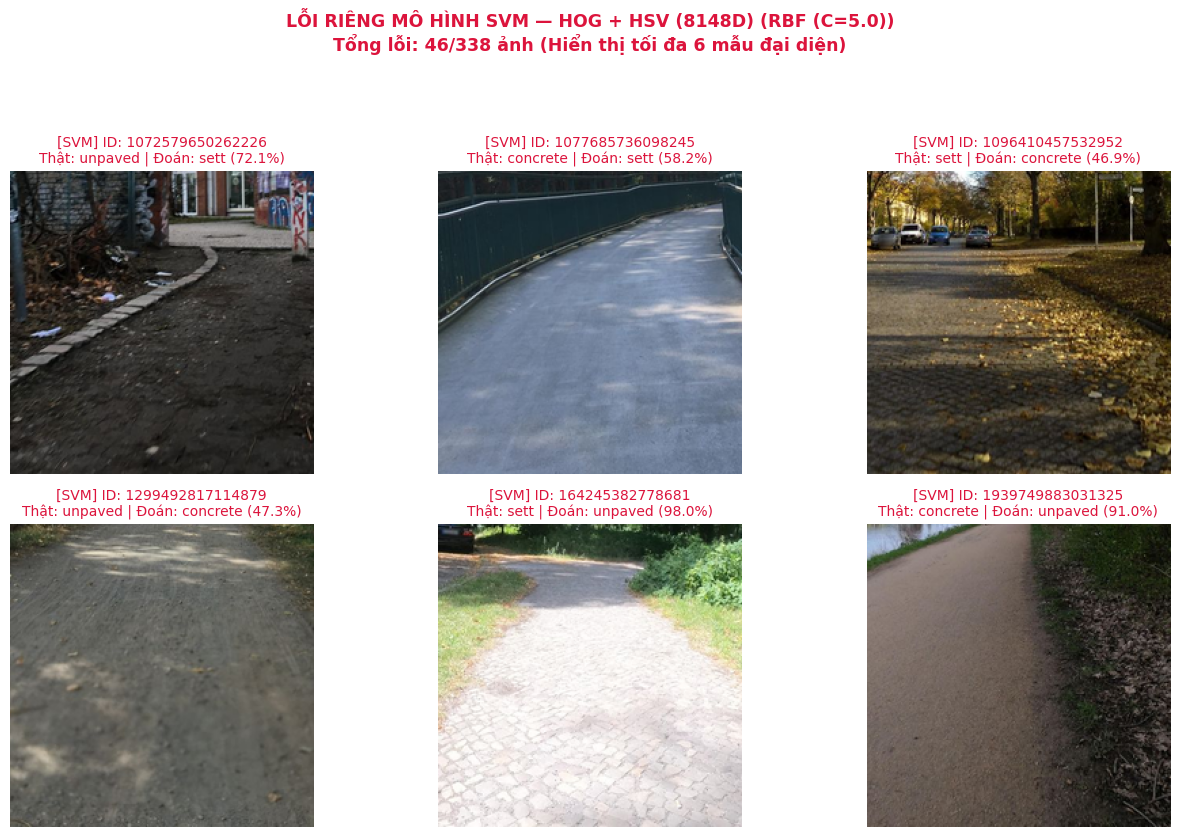

Đã lưu ảnh lỗi riêng của SVM tại: /kaggle/working/error_analysis_svm.png



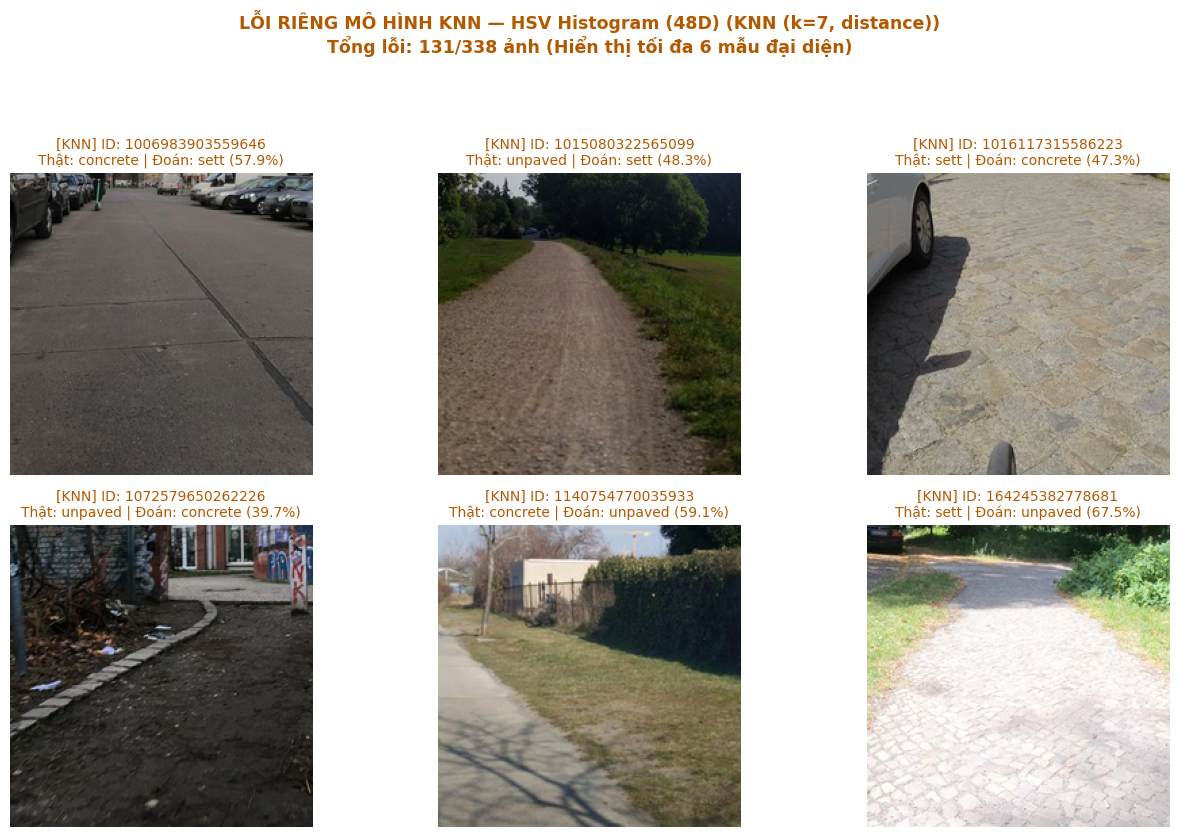

Đã lưu ảnh lỗi riêng của KNN tại: /kaggle/working/error_analysis_knn.png



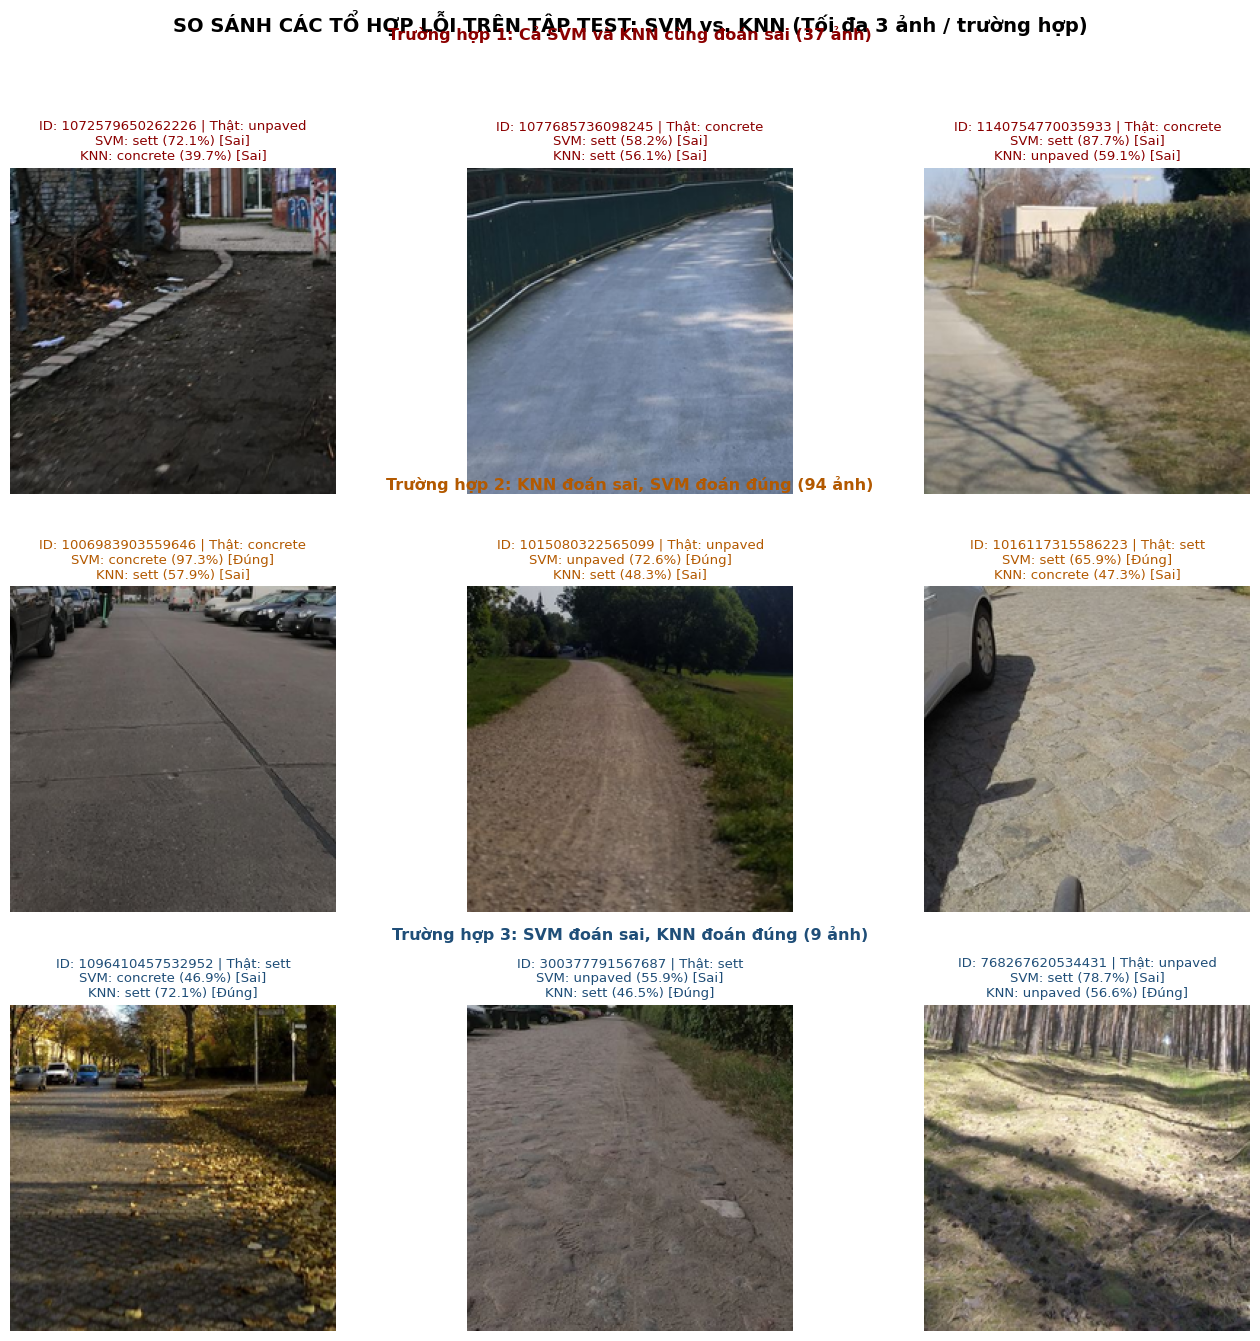

Đã lưu bảng lưới so sánh 3 tổ hợp lỗi tại: /kaggle/working/error_comparison_svm_vs_knn.png


In [8]:
import csv
import cv2
import joblib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

test_rows = [r for r in rows if r["split"].strip() == "test"]
n_total = len(y_test)

# 1. Nạp độc lập 2 bundle mô hình đã lưu ở Cell 8
svm_bundle = joblib.load("/kaggle/working/best_road_svm_bundle.joblib")
knn_bundle = joblib.load("/kaggle/working/best_road_knn_bundle.joblib")

X_test_svm = select_features(X_test, svm_bundle["feature_type"])
X_test_knn = select_features(X_test, knn_bundle["feature_type"])

y_pred_svm  = svm_bundle["model"].predict(X_test_svm)
y_proba_svm = svm_bundle["model"].predict_proba(X_test_svm)

y_pred_knn  = knn_bundle["model"].predict(X_test_knn)
y_proba_knn = knn_bundle["model"].predict_proba(X_test_knn)

# 2. Tính toán các tập chỉ số đúng / sai của từng mô hình và tổ hợp chéo
svm_wrong = (y_pred_svm != y_test)
knn_wrong = (y_pred_knn != y_test)

idx_both_wrong     = np.where(svm_wrong & knn_wrong)[0]       # Cả 2 cùng sai
idx_knn_wrong_only = np.where((~svm_wrong) & knn_wrong)[0]    # KNN sai, SVM đúng
idx_svm_wrong_only = np.where(svm_wrong & (~knn_wrong))[0]    # SVM sai, KNN đúng
idx_both_right     = np.where((~svm_wrong) & (~knn_wrong))[0] # Cả 2 cùng đúng

print("=========================================================================")
print(f"THỐNG KÊ TỔNG HỢP LỖI TRÊN TẬP TEST (TỔNG SỐ: {n_total} ẢNH)")
print("=========================================================================")
print(f"1. Tổng số ảnh SVM đoán sai       : {np.sum(svm_wrong):>3}/{n_total} ({np.mean(svm_wrong)*100:.2f}%)")
print(f"2. Tổng số ảnh KNN đoán sai       : {np.sum(knn_wrong):>3}/{n_total} ({np.mean(knn_wrong)*100:.2f}%)")
print("-------------------------------------------------------------------------")
print(f"3. Cả SVM và KNN cùng đoán sai    : {len(idx_both_wrong):>3}/{n_total} ({len(idx_both_wrong)/n_total*100:.2f}%)")
print(f"4. Chỉ KNN sai, SVM đoán đúng     : {len(idx_knn_wrong_only):>3}/{n_total} ({len(idx_knn_wrong_only)/n_total*100:.2f}%)")
print(f"5. Chỉ SVM sai, KNN đoán đúng     : {len(idx_svm_wrong_only):>3}/{n_total} ({len(idx_svm_wrong_only)/n_total*100:.2f}%)")
print(f"6. Cả SVM và KNN cùng đoán đúng   : {len(idx_both_right):>3}/{n_total} ({len(idx_both_right)/n_total*100:.2f}%)")
print("=========================================================================\n")

# Xuất toàn bộ danh sách ảnh có ít nhất 1 mô hình đoán sai ra CSV để tiện tra cứu khi viết báo cáo
any_wrong_indices = np.where(svm_wrong | knn_wrong)[0]
csv_log_path = "/kaggle/working/error_comparison_log_test.csv"
with open(csv_log_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "test_idx", "image_id", "group_id", "case",
        "ground_truth", "svm_pred", "svm_conf_pct", "knn_pred", "knn_conf_pct"
    ])
    for idx in any_wrong_indices:
        r = test_rows[idx]
        if svm_wrong[idx] and knn_wrong[idx]:
            case_label = "Both_Wrong"
        elif knn_wrong[idx]:
            case_label = "KNN_Wrong_SVM_Right"
        else:
            case_label = "SVM_Wrong_KNN_Right"
        s_p = int(y_pred_svm[idx])
        k_p = int(y_pred_knn[idx])
        writer.writerow([
            int(idx), r["image_id"], r.get("group_id", ""), case_label,
            CLASS_NAMES[int(y_test[idx])],
            CLASS_NAMES[s_p], round(float(y_proba_svm[idx][s_p]) * 100, 2),
            CLASS_NAMES[k_p], round(float(y_proba_knn[idx][k_p]) * 100, 2),
        ])
print(f"Đã xuất log chi tiết {len(any_wrong_indices)} ảnh lỗi tại: {csv_log_path}\n")


def select_diverse_samples(indices, max_items, signature_fn):
    """Ưu tiên chọn các mẫu đại diện cho các kiểu nhầm lẫn khác nhau."""
    selected = []
    seen_sigs = set()
    for idx in indices:
        sig = signature_fn(idx)
        if sig not in seen_sigs:
            selected.append(idx)
            seen_sigs.add(sig)
        if len(selected) == max_items:
            return selected
    for idx in indices:
        if len(selected) == max_items:
            break
        if idx not in selected:
            selected.append(idx)
    return selected


# =========================================================================
# PHẦN A: IN TỐI ĐA 6 ẢNH LỖI RIÊNG CỦA TỪNG MÔ HÌNH (SVM VÀ KNN)
# =========================================================================
def plot_single_model_errors(model_name, bundle, y_pred, y_proba, title_color):
    mis_indices = np.where(y_pred != y_test)[0]
    selected = select_diverse_samples(
        mis_indices,
        max_items=6,
        signature_fn=lambda i: (int(y_test[i]), int(y_pred[i]))
    )

    fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
    fig.suptitle(
        f"LỖI RIÊNG MÔ HÌNH {model_name} — {bundle['feature_name']} ({bundle['config_name']})\n"
        f"Tổng lỗi: {len(mis_indices)}/{n_total} ảnh (Hiển thị tối đa 6 mẫu đại diện)",
        fontsize=12.5, fontweight="bold", color=title_color, y=0.98
    )
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < len(selected):
            idx = selected[i]
            r = test_rows[idx]
            img_path = Path(DATA_ROOT) / r["image_path"].strip()
            img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

            true_name = CLASS_NAMES[int(y_test[idx])]
            pred_idx = int(y_pred[idx])
            pred_name = CLASS_NAMES[pred_idx]
            conf = y_proba[idx][pred_idx] * 100

            ax.imshow(img_rgb)
            ax.set_title(
                f"[{model_name}] ID: {r['image_id']}\n"
                f"Thật: {true_name} | Đoán: {pred_name} ({conf:.1f}%)",
                fontsize=10, color=title_color
            )
        ax.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    out_path = f"/kaggle/working/error_analysis_{model_name.lower()}.png"
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu ảnh lỗi riêng của {model_name} tại: {out_path}\n")


plot_single_model_errors("SVM", svm_bundle, y_pred_svm, y_proba_svm, "crimson")
plot_single_model_errors("KNN", knn_bundle, y_pred_knn, y_proba_knn, "#b35900")


# =========================================================================
# PHẦN B: IN TỐI ĐA 3 ẢNH CHO MỖI TỔ HỢP LỖI CHÉO GIỮA SVM VÀ KNN (LƯỚI 3x3)
# =========================================================================
comparison_cases = [
    (
        f"Trường hợp 1: Cả SVM và KNN cùng đoán sai ({len(idx_both_wrong)} ảnh)",
        idx_both_wrong,
        "#8b0000"  # Đỏ sẫm
    ),
    (
        f"Trường hợp 2: KNN đoán sai, SVM đoán đúng ({len(idx_knn_wrong_only)} ảnh)",
        idx_knn_wrong_only,
        "#b35900"  # Cam đậm
    ),
    (
        f"Trường hợp 3: SVM đoán sai, KNN đoán đúng ({len(idx_svm_wrong_only)} ảnh)",
        idx_svm_wrong_only,
        "#1f4e78"  # Xanh đậm
    ),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 13.5))
fig.suptitle(
    "SO SÁNH CÁC TỔ HỢP LỖI TRÊN TẬP TEST: SVM vs. KNN (Tối đa 3 ảnh / trường hợp)",
    fontsize=14, fontweight="bold", y=0.99
)

for row_idx, (case_title, case_indices, case_color) in enumerate(comparison_cases):
    selected = select_diverse_samples(
        case_indices,
        max_items=3,
        signature_fn=lambda i: (int(y_test[i]), int(y_pred_svm[i]), int(y_pred_knn[i]))
    )

    for col_idx in range(3):
        ax = axes[row_idx, col_idx]
        if col_idx < len(selected):
            idx = selected[col_idx]
            r = test_rows[idx]
            img_path = Path(DATA_ROOT) / r["image_path"].strip()
            img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

            true_idx  = int(y_test[idx])
            svm_idx   = int(y_pred_svm[idx])
            knn_idx   = int(y_pred_knn[idx])

            true_name = CLASS_NAMES[true_idx]
            svm_name  = CLASS_NAMES[svm_idx]
            knn_name  = CLASS_NAMES[knn_idx]

            svm_conf  = y_proba_svm[idx][svm_idx] * 100
            knn_conf  = y_proba_knn[idx][knn_idx] * 100

            svm_tag = "Đúng" if svm_idx == true_idx else "Sai"
            knn_tag = "Đúng" if knn_idx == true_idx else "Sai"

            ax.imshow(img_rgb)
            ax.set_title(
                f"ID: {r['image_id']} | Thật: {true_name}\n"
                f"SVM: {svm_name} ({svm_conf:.1f}%) [{svm_tag}]\n"
                f"KNN: {knn_name} ({knn_conf:.1f}%) [{knn_tag}]",
                fontsize=9.5, color=case_color, pad=6
            )
        else:
            # Nếu trường hợp có 0 ảnh, hiển thị thông báo ở ô giữa hàng đó
            if len(selected) == 0 and col_idx == 1:
                ax.text(
                    0.5, 0.5, "Không có mẫu nào\nthỏa điều kiện này",
                    ha="center", va="center", fontsize=11, style="italic", color="gray",
                    transform=ax.transAxes
                )
        ax.axis("off")

    # Đặt tiêu đề ngang cho từng hàng (mỗi hàng là 1 tổ hợp lỗi)
    row_y = 1.0 - (row_idx + 0.02) / 3.0
    fig.text(
        0.5, row_y - 0.015, case_title,
        ha="center", va="top", fontsize=11.5, fontweight="bold", color=case_color
    )

plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3.2)
comp_fig_path = "/kaggle/working/error_comparison_svm_vs_knn.png"
plt.savefig(comp_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Đã lưu bảng lưới so sánh 3 tổ hợp lỗi tại: {comp_fig_path}")